# Tracking aperture losses

In this notebook we turn the interpolated aperture from notebook 002 into
tracking elements, launch a Gaussian beam, and track it around the ring.

We restore the aperture definitions and placements with `env.aperture.from_json`, then
build `ring.aperture` before sampling the geometry for tracking limits.

The sequence is: install aperture limits, generate and track particles,
locate losses, then inspect them along the ring and in transverse/3D views.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xtrack as xt

# Load the lattice + the model
env = xt.load("toy_ring.json")
env.aperture.from_json("aperture_model.json")

ring = env["ring"]

# Keep a clean optics line for aperture queries and a separate copy for
# inserting the discrete tracking limits.
env.lines["tracking_ring"] = ring.copy()
tracking_ring = env.lines["tracking_ring"]

model = ring.aperture
model.build_model()

length = ring.get_length()
twiss = ring.twiss()

Loading line from dict:   0%|          | 0/84 [00:00<?, ?it/s]

Done loading line from dict.           
Done loading line from dict.           


Building cross-sections:   0%|          | 0/244 [00:00<?, ?it/s]

## Install aperture limits

`get_limit_elements_at_s` samples the interpolated aperture and returns ordinary
Xtrack `LimitPolygon` elements. We install one at each sampled longitudinal
position. We start simple with 1 metre sampling.

In [2]:
sample_s = np.arange(1, length, 1)

limit_elements = model.get_limit_elements_at_s(sample_s)

limit_s_by_name = {}
for idx, (s, element) in enumerate(limit_elements.items()):
    name = f"loss_limit_{idx}"
    tracking_ring.insert(what=name, obj=element, at=float(s), anchor="start", with_progress=False)
    limit_s_by_name[name] = s

tracking_ring.build_tracker()
print(f"Installed {len(limit_s_by_name)} aperture limits around the ring.")

Installed 104 aperture limits around the ring.


## Generate a Gaussian beam

Particles are sampled from a Gaussian in normalized transverse phase
space and matched to the linear Twiss optics at the ring start. The larger
emittances make the beam physically wider, so its natural Gaussian tails
can reach the aperture. A small momentum spread adds a dispersive
contribution. The aperture envelope plot uses these same emittances.

In [3]:
rng = np.random.default_rng(20260923)
num_particles = 10_000
nemitt_x = 20e-6
nemitt_y = 20e-6
delta_rms = 1.0e-4

model.halo_params['nemitt_x'] = nemitt_x
model.halo_params['nemitt_y'] = nemitt_y
model.halo_params['delta_rms'] = delta_rms

x_norm = rng.normal(size=num_particles)
px_norm = rng.normal(size=num_particles)
y_norm = rng.normal(size=num_particles)
py_norm = rng.normal(size=num_particles)

delta = rng.normal(0.0, delta_rms, num_particles)
particles = tracking_ring.build_particles(
    at_element=0,
    x_norm=x_norm,
    px_norm=px_norm,
    y_norm=y_norm,
    py_norm=py_norm,
    nemitt_x=nemitt_x,
    nemitt_y=nemitt_y,
    delta=delta,
)

print(
    f"Generated {num_particles:,} Gaussian particles with "
    f"nemitt_x = nemitt_y = {nemitt_x:.1e} m."
)

Generated 10,000 Gaussian particles with nemitt_x = nemitt_y = 2.0e-05 m.


## Track one turn and locate the losses

For this first pass, one turn is enough: the aim is to see where the
injected halo first encounters the aperture, rather than model a long-term
loss process. Xtrack records the lost-particle state at the explicit limit
element that stopped the particle.

In [4]:
tracking_ring.track(particles, num_turns=10, with_progress=1)
lost_mask = particles.state <= 0
lost_indices = np.flatnonzero(lost_mask)
element_names = np.asarray(tracking_ring.element_names, dtype=object)
loss_names = element_names[np.asarray(particles.at_element[lost_mask], dtype=int)]
loss_s = np.asarray([limit_s_by_name.get(name, np.nan) for name in loss_names])
valid = np.isfinite(loss_s)

losses = {
    "particle_id": np.asarray(particles.particle_id[lost_mask])[valid],
    "element": loss_names[valid],
    "s": loss_s[valid],
    "x": np.asarray(particles.x[lost_mask])[valid],
    "y": np.asarray(particles.y[lost_mask])[valid],
    "delta": np.asarray(particles.delta[lost_mask])[valid],
    "state": np.asarray(particles.state[lost_mask])[valid],
}

print(
    f"Lost {len(losses['s']):,} of {len(particles.particle_id):,} particles "
    f"({len(losses['s']) / len(particles.particle_id):.1%}) on the first turn."
)
print(f"Losses recorded at {len(np.unique(losses['element']))} distinct limits.")

Tracking:   0%|          | 0/10 [00:00<?, ?it/s]

Lost 611 of 10,000 particles (6.1%) on the first turn.
Losses recorded at 46 distinct limits.


## Where around the ring do particles hit?

The aperture/envelope extent plot gives the machine context. The histogram
beneath it shows how many tracked particles were stopped in each
one-metre bin. The loss positions are mesh locations, not continuous
impact coordinates.


Computing sigmas: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

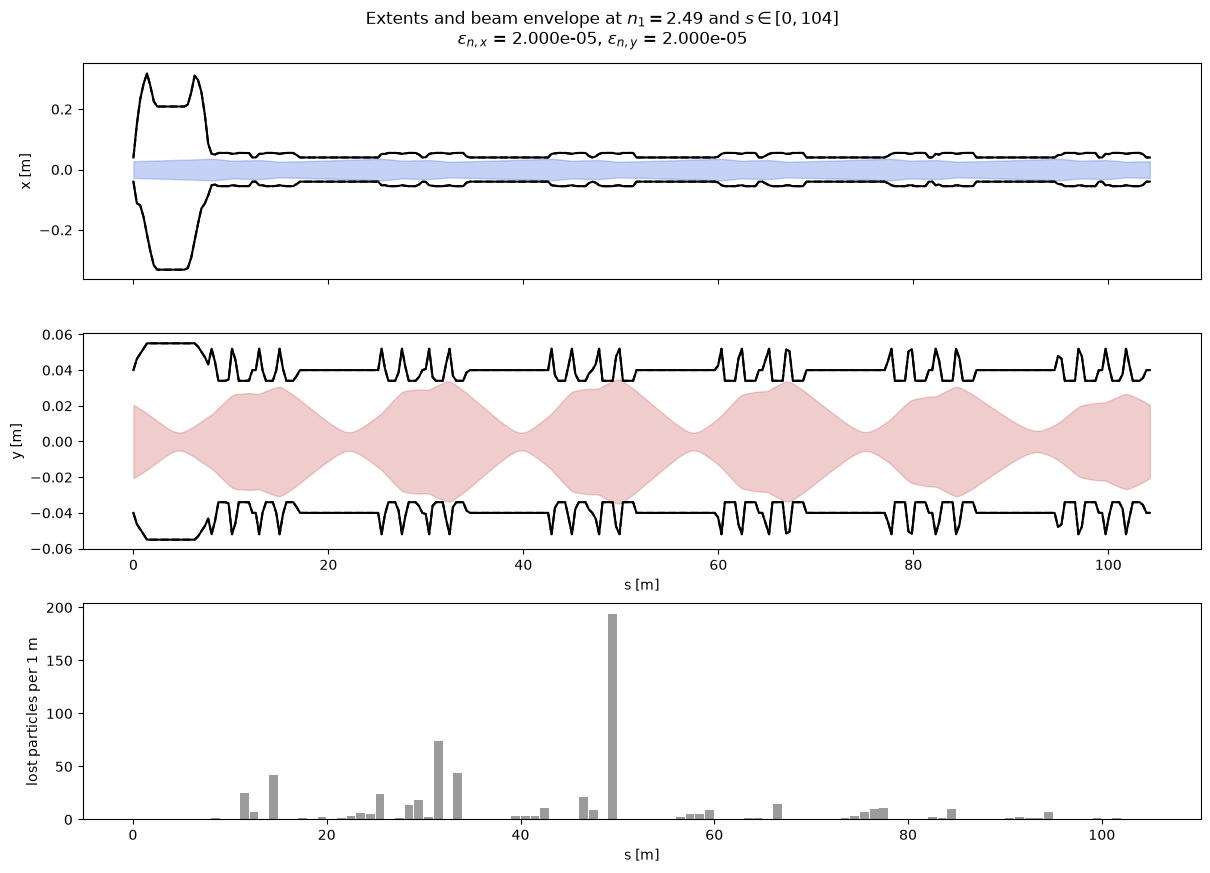

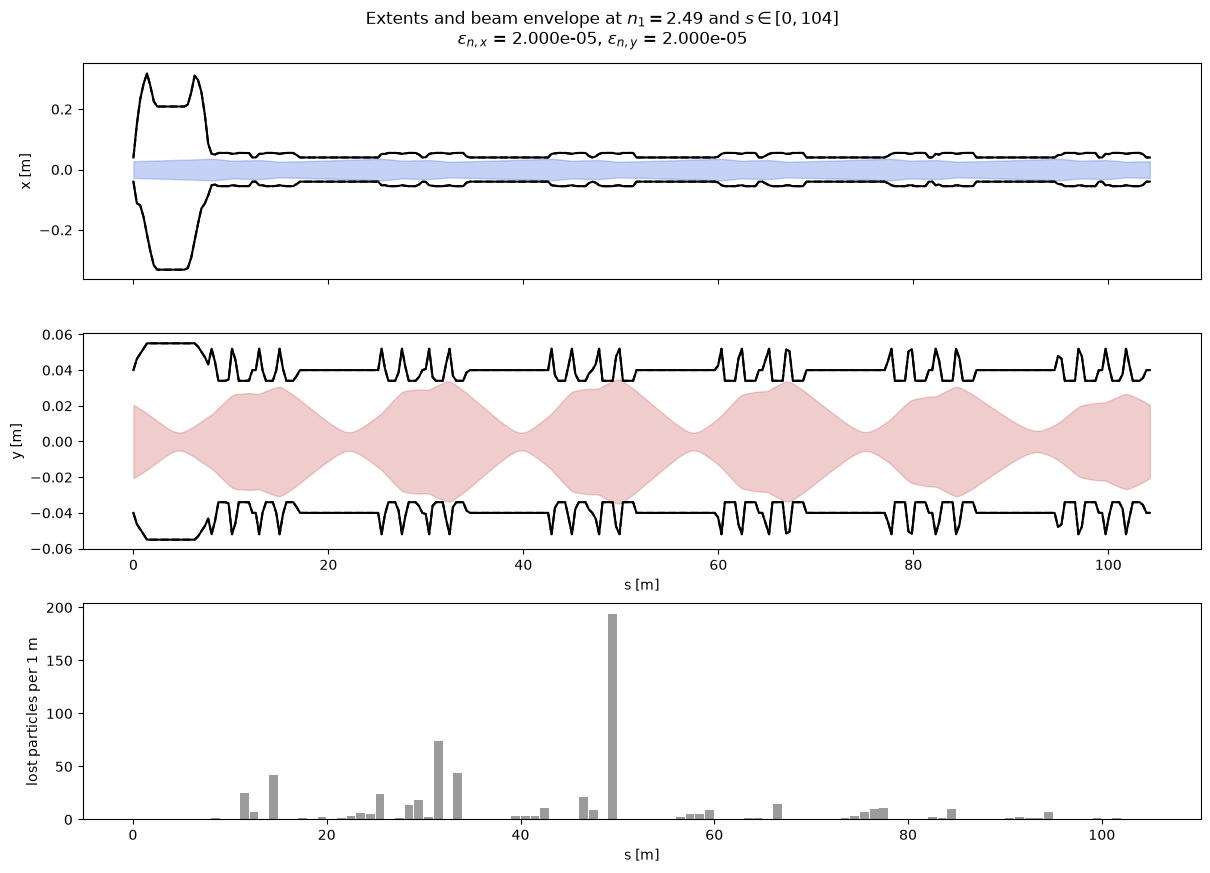

In [5]:
# Sample the ring finely to draw the aperture and beam envelopes.
extent_s = np.linspace(0.0, length, 300)
extent_fig, extent_axes = model.plot_extents(
    s_positions=extent_s,
    include_aper_tols=True,
    with_progress=False,
)
# Bin first-impact locations by metre for a comparable loss profile.
_bins = np.arange(0.0, length + 1.0, 1.0)
_counts, _edges = np.histogram(losses["s"], bins=_bins)
_centres = (_edges[:-1] + _edges[1:]) / 2
# Reflow the two aperture panels to make room for a separate loss-count row.
extent_fig.set_size_inches(13, 9)
extent_axes[0].set_position([0.10, 0.68, 0.86, 0.24])
extent_axes[1].set_position([0.10, 0.38, 0.86, 0.24])
loss_count_ax = extent_fig.add_axes([0.10, 0.08, 0.86, 0.24])
loss_count_ax.bar(
    _centres, _counts, width=0.9, color="#7a7a7a", alpha=0.75,
    label="lost particles / 1 m",
)
loss_count_ax.set_ylabel("lost particles per 1 m")
loss_count_ax.set_xlabel("s [m]")
extent_axes[0].set_ylabel("x [m]")
extent_axes[1].set_ylabel("y [m]")
extent_axes[1].set_xlabel("s [m]")
extent_fig

## Inspect one transverse cross-section

Choose the most populated loss station. The polygon is the installed
aperture section at that station; the points are particles stopped there,
in the local transverse coordinates used by the tracking element.


Interpolating profiles: 100%

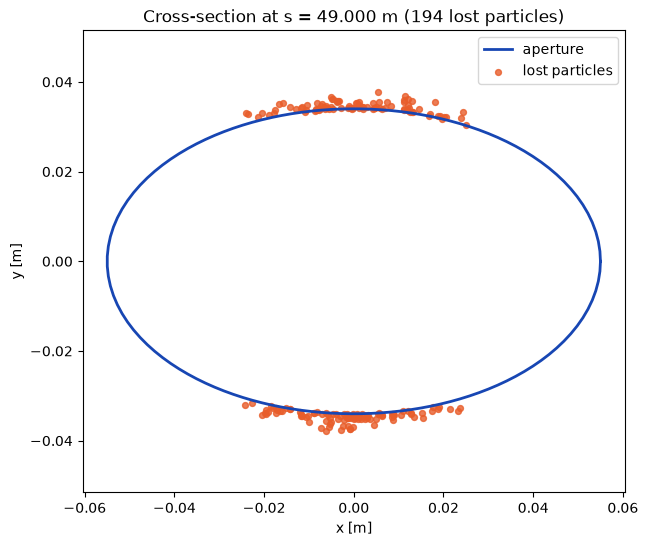

In [6]:
# Select the busiest loss station so the cross-section contains many impacts.
unique_s, counts = np.unique(losses["s"], return_counts=True)
focus_s = float(unique_s[np.argmax(counts)])
focus_mask = losses["s"] == focus_s
section = model.get_cross_sections_at_s(np.asarray([focus_s]), extents=True)
polygon = section.cross_section[0]

# Overlay local impact coordinates on the aperture boundary at this station.
section_fig, section_ax = plt.subplots(figsize=(7, 6))
section_ax.plot(polygon[:, 0], polygon[:, 1], color="#1746b3", lw=2, label="aperture")
section_ax.scatter(
    losses["x"][focus_mask], losses["y"][focus_mask],
    s=18, color="#e85d2a", alpha=0.8, label="lost particles",
)
section_ax.set_aspect("equal", adjustable="datalim")
section_ax.set_xlabel("x [m]")
section_ax.set_ylabel("y [m]")
section_ax.set_title(
    f"Cross-section at s = {focus_s:.3f} m "
    f"({focus_mask.sum()} lost particles)"
)
section_ax.legend();

## Overlay impact points on the aperture in 3D

The selected short window is centred on the busiest loss station. Each
cross-section and impact point is transformed from its local beam frame to
the global survey frame using the aperture model's pose. The grey outlines
show the pipe; orange points show impacts. The view is intentionally local
so the chamber shape and loss locations remain visible.


Interpolating profiles: 100%
Interpolating profiles: 100%

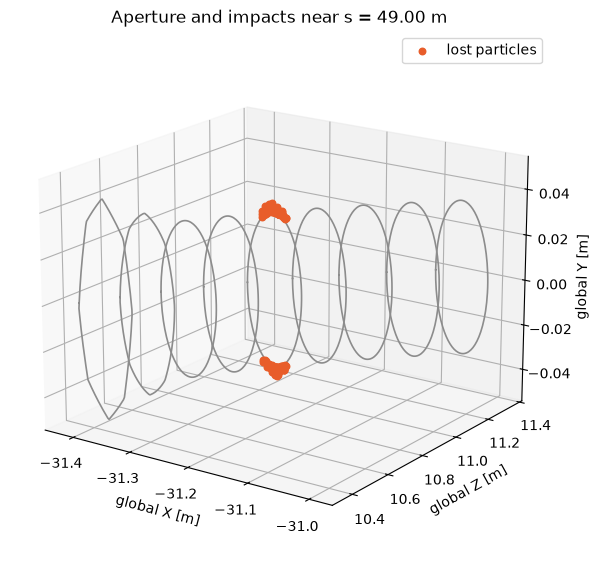

In [8]:
# A short window makes the chamber bend visible around the busiest station.
half_window = 0.5
window_s = np.linspace(
    max(0.0, focus_s - half_window),
    min(length, focus_s + half_window),
    9,
)
window_sections = model.get_cross_sections_at_s(window_s, extents=False)
in_window = np.abs(losses["s"] - focus_s) <= half_window

spatial_fig = plt.figure(figsize=(9, 7))
# Matplotlib uses its third coordinate as vertical; map global Y there.
spatial_ax = spatial_fig.add_subplot(111, projection="3d")
# Transform each local aperture polygon into global survey coordinates.
for _row in window_sections.rows:
    _poly = _row.cross_section
    _local = np.column_stack((_poly[:, 0], _poly[:, 1], np.zeros(len(_poly)), np.ones(len(_poly))))
    _global = _local @ _row.pose.T
    spatial_ax.plot(_global[:, 0], _global[:, 2], _global[:, 1], color="0.55", lw=1.2)

# Transform local impact coordinates using the pose at each loss station.
_impact_s = losses["s"][in_window]
_unique_impact_s, _inverse = np.unique(_impact_s, return_inverse=True)
_impact_sections = model.get_cross_sections_at_s(_unique_impact_s, extents=False)
_impacts_xyz = []
_impact_x = losses["x"][in_window]
_impact_y = losses["y"][in_window]
for _i, _row in enumerate(_impact_sections.rows):
    _at_section = _inverse == _i
    _local_hits = np.column_stack((
        _impact_x[_at_section], _impact_y[_at_section],
        np.zeros(_at_section.sum()), np.ones(_at_section.sum()),
    ))
    _impacts_xyz.extend((_local_hits @ _row.pose.T)[:, :3])
if _impacts_xyz:
    _impacts_xyz = np.asarray(_impacts_xyz)
    spatial_ax.scatter(
        _impacts_xyz[:, 0], _impacts_xyz[:, 2], _impacts_xyz[:, 1],
        color="#e85d2a", s=22, depthshade=False, label="lost particles",
    )

# Change the viewpoint for a better picture
spatial_ax.view_init(elev=18, azim=-55)
spatial_ax.set_xlabel("global X [m]")
spatial_ax.set_ylabel("global Z [m]")
spatial_ax.set_zlabel("global Y [m]")
spatial_ax.set_title(f"Aperture and impacts near s = {focus_s:.2f} m")
spatial_ax.legend(loc="best");